<a href="https://colab.research.google.com/github/Kellaikram/GNN-Intrusion-Detection/blob/main/projetstructure.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# importation des biblio


In [ ]:
import pandas as pd
import torch
from torch_geometric.data import Data
from torch_geometric.nn import GATConv, SAGEConv
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_curve, auc


/usr/local/lib/python3.11/dist-packages/torch_geometric/typing.py:86: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: /usr/local/lib/python3.11/dist-packages/torch_scatter/_version_cuda.so: undefined symbol: _ZN3c1017RegisterOperatorsD1Ev
  warnings.warn(f"An issue occurred while importing 'torch-scatter'. "
/usr/local/lib/python3.11/dist-packages/torch_geometric/typing.py:97: UserWarning: An issue occurred while importing 'torch-cluster'. Disabling its usage. Stacktrace: /usr/local/lib/python3.11/dist-packages/torch_cluster/_version_cuda.so: undefined symbol: _ZN3c1017RegisterOperatorsD1Ev
  warnings.warn(f"An issue occurred while importing 'torch-cluster'. "
/usr/local/lib/python3.11/dist-packages/torch_geometric/typing.py:113: UserWarning: An issue occurred while importing 'torch-spline-conv'. Disabling its usage. Stacktrace: /usr/local/lib/python3.11/dist-packages/torch_spline_conv/_version_cuda.so: undefined symbol: _ZN3c1017Registe

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# importation Data

In [ ]:
col_names = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land",
    "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in", "num_compromised",
    "root_shell", "su_attempted", "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
    "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label"
]

df = pd.read_csv("/content/drive/MyDrive/projetStructure/kddcup.data_10_percent_corrected", names=col_names)
df.head()



,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label
0,0,tcp,http,SF,181,5450,0,0,0,0,...,9,1.0,0.0,0.11,0.0,0.0,0.0,0.0,0.0,normal.
1,0,tcp,http,SF,239,486,0,0,0,0,...,19,1.0,0.0,0.05,0.0,0.0,0.0,0.0,0.0,normal.
2,0,tcp,http,SF,235,1337,0,0,0,0,...,29,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0,normal.
3,0,tcp,http,SF,219,1337,0,0,0,0,...,39,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0,normal.
4,0,tcp,http,SF,217,2032,0,0,0,0,...,49,1.0,0.0,0.02,0.0,0.0,0.0,0.0,0.0,normal.


# Encodage des colonnes catégorielles

In [ ]:
categorical_cols = ["protocol_type", "service", "flag"]
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

# Affichage du traitement effectué
    print(f"\n--- Encodage de la colonne '{col}' ---")
    print("Valeurs uniques d'origine :", list(le.classes_))
    print("Valeurs encodées associées :", list(range(len(le.classes_))))
    print("Aperçu du résultat après encodage :", df[col].head().tolist())


--- Encodage de la colonne 'protocol_type' ---
Valeurs uniques d'origine : ['icmp', 'tcp', 'udp']
Valeurs encodées associées : [0, 1, 2]
Aperçu du résultat après encodage : [1, 1, 1, 1, 1]

--- Encodage de la colonne 'service' ---
Valeurs uniques d'origine : ['IRC', 'X11', 'Z39_50', 'auth', 'bgp', 'courier', 'csnet_ns', 'ctf', 'daytime', 'discard', 'domain', 'domain_u', 'echo', 'eco_i', 'ecr_i', 'efs', 'exec', 'finger', 'ftp', 'ftp_data', 'gopher', 'hostnames', 'http', 'http_443', 'imap4', 'iso_tsap', 'klogin', 'kshell', 'ldap', 'link', 'login', 'mtp', 'name', 'netbios_dgm', 'netbios_ns', 'netbios_ssn', 'netstat', 'nnsp', 'nntp', 'ntp_u', 'other', 'pm_dump', 'pop_2', 'pop_3', 'printer', 'private', 'red_i', 'remote_job', 'rje', 'shell', 'smtp', 'sql_net', 'ssh', 'sunrpc', 'supdup', 'systat', 'telnet', 'tftp_u', 'tim_i', 'time', 'urh_i', 'urp_i', 'uucp', 'uucp_path', 'vmnet', 'whois']
Valeurs encodées associées : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,

# Encodage binaire du label : normal. = normal / les autres = attack

In [ ]:
# Avant traitement
print("\n--- Avant traitement de la colonne 'label' ---")
print(df["label"].value_counts())

df["label"] = df["label"].apply(lambda x: "normal" if x == "normal." else "attack")
# Après traitement
print("\n--- Après traitement de la colonne 'label' ---")
print(df["label"].value_counts())




--- Avant traitement de la colonne 'label' ---
label
smurf.              280790
neptune.            107201
normal.              97278
back.                 2203
satan.                1589
ipsweep.              1247
portsweep.            1040
warezclient.          1020
teardrop.              979
pod.                   264
nmap.                  231
guess_passwd.           53
buffer_overflow.        30
land.                   21
warezmaster.            20
imap.                   12
rootkit.                10
loadmodule.              9
ftp_write.               8
multihop.                7
phf.                     4
perl.                    3
spy.                     2
Name: count, dtype: int64

--- Après traitement de la colonne 'label' ---
label
attack    396743
normal     97278
Name: count, dtype: int64


# Séparer X et y

In [ ]:
# Transformation de la cible : 'attack' -> 1, 'normal' -> 0

y = (df['label'] == 'attack').astype(int)

# Affichage du résultat de la transformation
print("\n--- Transformation de la variable cible 'label' ---")
print("Valeurs uniques dans y :", y.unique())
print("Nombre d'attaques (1) :", (y == 1).sum())
print("Nombre de normales (0) :", (y == 0).sum())

#Suppression de la colonne 'label' pour créer X

X = df.drop("label", axis=1)

# Affichage de la forme de X et de y
print("\n--- Dimensions des données ---")
print("X (features) :", X.shape)
print("y (cible)    :", y.shape)


--- Transformation de la variable cible 'label' ---
Valeurs uniques dans y : [0 1]
Nombre d'attaques (1) : 396743
Nombre de normales (0) : 97278

--- Dimensions des données ---
X (features) : (494021, 41)
y (cible)    : (494021,)


# Standardisation

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Affichage du traitement effectué
print("\n--- Standardisation des données ---")
print("Moyenne de chaque colonne (après scaling) :", X_scaled.mean(axis=0)[:5])  # affiche les 5 premières moyennes
print("Écart-type de chaque colonne (après scaling) :", X_scaled.std(axis=0)[:5])  # affiche les 5 premiers écart-types

# Optionnel : aperçu des 5 premières lignes de X après scaling
print("\nAperçu des 5 premières lignes des données standardisées :")
print(X_scaled[:5])



--- Standardisation des données ---
Moyenne de chaque colonne (après scaling) : [ 2.17180956e-17 -1.64769870e-16 -3.25627606e-17 -3.58995806e-17
  6.50823726e-19]
Écart-type de chaque colonne (après scaling) : [1. 1. 1. 1. 1.]

Aperçu des 5 premières lignes des données standardisées :
[[-6.77917205e-02  9.25753062e-01 -1.04067101e-01  5.14273922e-01
  -2.87852770e-03  1.38664408e-01 -6.67341765e-03 -4.77201854e-02
  -2.57146810e-03 -4.41359116e-02 -9.78218463e-03  2.39697959e+00
  -5.67868416e-03 -1.05519522e-02 -4.67567073e-03 -5.64001207e-03
  -1.12320815e-02 -9.91897493e-03 -2.76318157e-02  0.00000000e+00
   0.00000000e+00 -3.72626624e-02 -1.52141663e+00 -1.15664009e+00
  -4.64089752e-01 -4.63520471e-01 -2.47960476e-01 -2.48631282e-01
   5.36987403e-01 -2.55243389e-01 -2.03633068e-01 -3.45153588e+00
  -1.69431452e+00  5.99396187e-01 -2.82866677e-01 -1.02207729e+00
  -1.58629293e-01 -4.64417626e-01 -4.63202392e-01 -2.52039522e-01
  -2.49464005e-01]
 [-6.77917205e-02  9.25753062e-01 

In [ ]:
df.isnull().sum()

,0
duration,0
protocol_type,0
service,0
flag,0
src_bytes,0
dst_bytes,0
land,0
wrong_fragment,0
urgent,0
hot,0


In [ ]:
print("\n--- Dimensions des jeux de données ---")
print("X (features) :", X.shape)
print("y (cible)    :", y.shape)




--- Dimensions des jeux de données ---
X (features) : (494021, 41)
y (cible)    : (494021,)


# Créer un "graph" factice pour PyG

## Construction des edges (indices source → cible)

In [ ]:
k = 5
nbrs = NearestNeighbors(n_neighbors=k+1, algorithm='auto').fit(X_scaled)
distances, indices = nbrs.kneighbors(X_scaled)

# Affichage des résultats
print("\n--- Recherche des plus proches voisins ---")
print(f"Nombre de voisins recherchés (k+1) : {k + 1}")
print("Aperçu des indices des voisins (première ligne) :", indices[0])
print("Aperçu des distances correspondantes :", distances[0])



--- Recherche des plus proches voisins ---
Nombre de voisins recherchés (k+1) : 6
Aperçu des indices des voisins (première ligne) : [     0  30815  22957 396828 104343 104091]
Aperçu des distances correspondantes : [0.         0.05178728 0.08107231 0.08180568 0.08418236 0.08558104]


In [ ]:
distances,nbrs

(array([[0.00000000e+00, 5.17872839e-02, 8.10723107e-02, 8.18056821e-02,
         8.41823648e-02, 8.55810391e-02],
        [0.00000000e+00, 2.65738851e-02, 4.12393903e-02, 4.57854733e-02,
         4.70926923e-02, 4.99511377e-02],
        [0.00000000e+00, 1.91747299e-02, 2.57566870e-02, 4.36630306e-02,
         4.67974344e-02, 4.91144753e-02],
        ...,
        [8.42936970e-08, 2.97413668e-01, 3.52134231e-01, 3.57582307e-01,
         3.90857594e-01, 4.69865987e-01],
        [0.00000000e+00, 1.11297875e-01, 1.34200071e-01, 1.34702414e-01,
         1.35739204e-01, 1.39757409e-01],
        [0.00000000e+00, 6.06161438e-02, 1.10164019e-01, 1.11994095e-01,
         1.16812254e-01, 1.17320386e-01]]),
 NearestNeighbors(n_neighbors=6))

In [ ]:
edge_index = []
for idx, neighbors in enumerate(indices):
    for neighbor in neighbors[1:]:  # on ignore le premier car c'est lui-même
        edge_index.append([idx, neighbor])

# Affiche pour les premiers indices (par exemple, idx < 5)
    if idx < 5:
        print(f"Pour le noeud {idx}, voisins retenus (sans lui-même) : {neighbors[1:].tolist()}")

edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()
print("\n--- Résultat final ---")
print(f"Forme de edge_index : {edge_index.shape}")
print(f"Exemple de colonnes dans edge_index (5 premiers liens) :\n{edge_index[:, :5]}")


Pour le noeud 0, voisins retenus (sans lui-même) : [30815, 22957, 396828, 104343, 104091]
Pour le noeud 1, voisins retenus (sans lui-même) : [18538, 104092, 31221, 83022, 6592]
Pour le noeud 2, voisins retenus (sans lui-même) : [396830, 18539, 6593, 23282, 19435]
Pour le noeud 3, voisins retenus (sans lui-même) : [3611, 23283, 19436, 798, 486079]
Pour le noeud 4, voisins retenus (sans lui-même) : [15150, 31224, 3612, 799, 6904]

--- Résultat final ---
Forme de edge_index : torch.Size([2, 2470105])
Exemple de colonnes dans edge_index (5 premiers liens) :
tensor([[     0,      0,      0,      0,      0],
        [ 30815,  22957, 396828, 104343, 104091]])


## Convertir X_scaled et y en tensors

In [ ]:
X_tensor = torch.tensor(X_scaled, dtype=torch.float)
y_tensor = torch.tensor(y.values, dtype=torch.long)

# Affichage du résultat
print("\n--- Conversion en tenseurs PyTorch ---")
print(f"Type de X_tensor : {type(X_tensor)}")
print(f"Dimension de X_tensor : {X_tensor.shape}")
print(f"Type de y_tensor : {type(y_tensor)}")
print(f"Dimension de y_tensor : {y_tensor.shape}")
print(f"Aperçu des 5 premiers éléments de y_tensor : {y_tensor[:5]}")


--- Conversion en tenseurs PyTorch ---
Type de X_tensor : <class 'torch.Tensor'>
Dimension de X_tensor : torch.Size([494021, 41])
Type de y_tensor : <class 'torch.Tensor'>
Dimension de y_tensor : torch.Size([494021])
Aperçu des 5 premiers éléments de y_tensor : tensor([0, 0, 0, 0, 0])


## Créer l'objet Data de PyG

In [ ]:
data = Data(x=X_tensor, edge_index=edge_index, y=y_tensor)
# Affichage du contenu
print("\n--- Objet PyTorch Geometric Data créé ---")
print(f"x (features) : type={type(data.x)}, shape={data.x.shape}")
print(f"edge_index (graphe) : type={type(data.edge_index)}, shape={data.edge_index.shape}")
print(f"y (labels) : type={type(data.y)}, shape={data.y.shape}")

# Aperçu des 5 premiers noeuds
print("\nAperçu des 5 premières features :")
print(data.x[:5])

print("\nAperçu des 5 premières arêtes (colonnes d'edge_index) :")
print(data.edge_index[:, :5])

print("\nAperçu des 5 premiers labels :")
print(data.y[:5])


--- Objet PyTorch Geometric Data créé ---
x (features) : type=<class 'torch.Tensor'>, shape=torch.Size([494021, 41])
edge_index (graphe) : type=<class 'torch.Tensor'>, shape=torch.Size([2, 2470105])
y (labels) : type=<class 'torch.Tensor'>, shape=torch.Size([494021])

Aperçu des 5 premières features :
tensor([[-6.7792e-02,  9.2575e-01, -1.0407e-01,  5.1427e-01, -2.8785e-03,
          1.3866e-01, -6.6734e-03, -4.7720e-02, -2.5715e-03, -4.4136e-02,
         -9.7822e-03,  2.3970e+00, -5.6787e-03, -1.0552e-02, -4.6757e-03,
         -5.6400e-03, -1.1232e-02, -9.9190e-03, -2.7632e-02,  0.0000e+00,
          0.0000e+00, -3.7263e-02, -1.5214e+00, -1.1566e+00, -4.6409e-01,
         -4.6352e-01, -2.4796e-01, -2.4863e-01,  5.3699e-01, -2.5524e-01,
         -2.0363e-01, -3.4515e+00, -1.6943e+00,  5.9940e-01, -2.8287e-01,
         -1.0221e+00, -1.5863e-01, -4.6442e-01, -4.6320e-01, -2.5204e-01,
         -2.4946e-01],
        [-6.7792e-02,  9.2575e-01, -1.0407e-01,  5.1427e-01, -2.8198e-03,
       

# Séparer train/validation/test

In [ ]:
indices = list(range(data.num_nodes))
train_idx, temp_idx = train_test_split(indices, test_size=0.3, random_state=42)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, random_state=42)
train_idx = torch.tensor(train_idx, dtype=torch.long)
val_idx = torch.tensor(val_idx, dtype=torch.long)
test_idx = torch.tensor(test_idx, dtype=torch.long)

# Affichage des tailles des ensembles
print("\n--- Répartition des indices ---")
print(f"Nombre total de noeuds : {data.num_nodes}")
print(f"Taille train : {train_idx.size(0)}")
print(f"Taille validation : {val_idx.size(0)}")
print(f"Taille test : {test_idx.size(0)}")

# Aperçu des premiers indices pour chaque ensemble
print("\nExemple d'indices train :", train_idx[:5].tolist())
print("Exemple d'indices validation :", val_idx[:5].tolist())
print("Exemple d'indices test :", test_idx[:5].tolist())



--- Répartition des indices ---
Nombre total de noeuds : 494021
Taille train : 345814
Taille validation : 74103
Taille test : 74104

Exemple d'indices train : [228201, 483696, 234556, 127627, 463534]
Exemple d'indices validation : [69996, 72521, 347478, 246768, 93383]
Exemple d'indices test : [16460, 246663, 185019, 41978, 57032]


# Installer PyTorch


In [ ]:

!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118


Looking in indexes: https://download.pytorch.org/whl/cu118


# Installer PyTorch Geometric (les packages spécifiques)

In [ ]:
!pip install torch-scatter -f https://data.pyg.org/whl/torch-2.1.0+cu118.html
!pip install torch-sparse -f https://data.pyg.org/whl/torch-2.1.0+cu118.html
!pip install torch-cluster -f https://data.pyg.org/whl/torch-2.1.0+cu118.html
!pip install torch-spline-conv -f https://data.pyg.org/whl/torch-2.1.0+cu118.html
!pip install torch-geometric


Looking in links: https://data.pyg.org/whl/torch-2.1.0+cu118.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 63.7 MB/s eta 0:00:00
Looking in links: https://data.pyg.org/whl/torch-2.1.0+cu118.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 37.2 MB/s eta 0:00:00
Looking in links: https://data.pyg.org/whl/torch-2.1.0+cu118.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 8.9 MB/s eta 0:00:00
Looking in links: https://data.pyg.org/whl/torch-2.1.0+cu118.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 891.8/891.8 kB 3.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 19.9 MB/s eta 0:00:00


# definition des modeles Graphes(GAT,SAGE)

In [ ]:
class GATNet(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super(GATNet, self).__init__()
        self.conv1 = GATConv(in_channels, hidden_channels, heads=2, dropout=0.3)
        self.conv2 = GATConv(hidden_channels * 2, out_channels, heads=1, concat=False, dropout=0.3)

    def forward(self, x, edge_index):
        print(f"\n[Forward] Entrée x shape : {x.shape}")

        x = self.conv1(x, edge_index)
        print(f"[Forward] Après conv1 (GATConv) x shape : {x.shape}")

        x = F.elu(x)
        print(f"[Forward] Après activation ELU x shape : {x.shape}")

        x = self.conv2(x, edge_index)
        print(f"[Forward] Après conv2 (GATConv) x shape : {x.shape}")

        return x

In [ ]:
class SAGENet(torch.nn.Module):
   def __init__(self, in_channels, hidden_channels, out_channels):
        super(SAGENet, self).__init__()
        self.conv1 = SAGEConv(in_channels, hidden_channels)
        self.dropout = torch.nn.Dropout(0.3)
        self.conv2 = SAGEConv(hidden_channels, out_channels)

   def forward(self, x, edge_index):
        print(f"\n[Forward] Entrée x shape : {x.shape}")

        x = self.conv1(x, edge_index)
        print(f"[Forward] Après conv1 (SAGEConv) x shape : {x.shape}")

        x = F.relu(x)
        print(f"[Forward] Après activation ReLU x shape : {x.shape}")

        x = self.dropout(x)
        print(f"[Forward] Après Dropout x shape : {x.shape}")

        x = self.conv2(x, edge_index)
        print(f"[Forward] Après conv2 (SAGEConv) x shape : {x.shape}")

        return x

# Définir la fonction 'train' et 'test'

In [ ]:
def train(model, data, train_idx, optimizer, criterion):
    model.train()
    optimizer.zero_grad()

    print("\n--- Début de la passe forward ---")
    out = model(data.x, data.edge_index)
    print(f"Sortie du modèle (logits) shape : {out.shape}")

    loss = criterion(out[train_idx], data.y[train_idx])
    print(f"Calcul de la loss sur les indices d'entraînement ({len(train_idx)} exemples) : {loss.item():.4f}")

    loss.backward()
    print("Rétropropagation effectuée.")

    optimizer.step()
    print("Optimiseur mis à jour.")

    return loss.item()


In [ ]:
def test(model, data, idxs):
    model.eval()
    print("\n--- Evaluation du modèle ---")

    out = model(data.x, data.edge_index)
    print(f"Sortie du modèle (logits) shape : {out.shape}")

    pred = out.argmax(dim=1)
    print(f"Prédictions (indices max) shape : {pred.shape}")

    correct = (pred[idxs] == data.y[idxs]).sum()
    acc = int(correct) / len(idxs)
    print(f"Nombre correct sur {len(idxs)} exemples : {correct.item()}")
    print(f"Exactitude (accuracy) calculée : {acc:.4f}")

    # Scores pour la classe positive (colonne 1) pour ROC
    scores = out[idxs][:, 1] if out.size(1) > 1 else out[idxs].squeeze()

    return acc, pred[idxs], data.y[idxs], scores


# Entrainer et tester les deux modeles GAT et SAGE

In [ ]:
def run_model(ModelClass, name):
    model = ModelClass(in_channels=data.num_node_features, hidden_channels=64, out_channels=2)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=5e-4)
    criterion = torch.nn.CrossEntropyLoss()
    losses = []

    for epoch in range(1, 101):
         loss = train(model, data, train_idx, optimizer, criterion)
         losses.append(loss)
         if epoch % 10 == 0:
             print(f'{name} - Epoch {epoch}, Loss: {loss:.4f}')



    # Test sur test set
    acc, preds, labels, probs = test(model, data, test_idx)
    print(f"\n\U0001f4ca Accuracy {name}: {acc * 100:.2f}%")
    print(classification_report(labels.cpu(), preds.cpu(), target_names=["normal", "attack"]))

    # Matrice de confusion
    cm = confusion_matrix(labels.cpu(), preds.cpu())
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues' if name == "GAT" else 'Greens')
    plt.title(f'Matrice de confusion - {name}')
    plt.xlabel('Prédit')
    plt.ylabel('Réel')
    plt.show()

    # Courbe de perte
    plt.plot(losses)
    plt.title(f'Courbe de Loss - {name}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.show()

    # ROC-AUC
    fpr, tpr, _ = roc_curve(labels.cpu().detach().numpy(), probs.cpu().detach().numpy())
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()
    plt.show()


--- Début de la passe forward ---

[Forward] Entrée x shape : torch.Size([494021, 41])
[Forward] Après conv1 (GATConv) x shape : torch.Size([494021, 128])
[Forward] Après activation ELU x shape : torch.Size([494021, 128])
[Forward] Après conv2 (GATConv) x shape : torch.Size([494021, 2])
Sortie du modèle (logits) shape : torch.Size([494021, 2])
Calcul de la loss sur les indices d'entraînement (345814 exemples) : 0.9807
Rétropropagation effectuée.
Optimiseur mis à jour.

--- Début de la passe forward ---

[Forward] Entrée x shape : torch.Size([494021, 41])
[Forward] Après conv1 (GATConv) x shape : torch.Size([494021, 128])
[Forward] Après activation ELU x shape : torch.Size([494021, 128])
[Forward] Après conv2 (GATConv) x shape : torch.Size([494021, 2])
Sortie du modèle (logits) shape : torch.Size([494021, 2])
Calcul de la loss sur les indices d'entraînement (345814 exemples) : 0.6669
Rétropropagation effectuée.
Optimiseur mis à jour.

--- Début de la passe forward ---

[Forward] Entrée

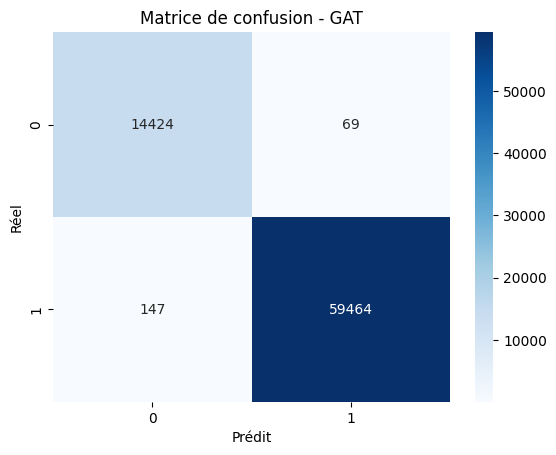

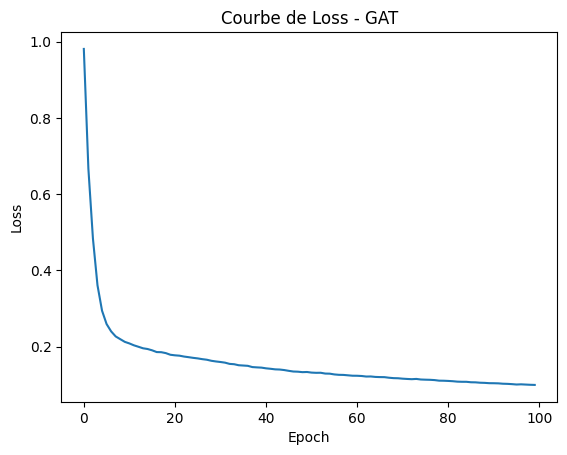

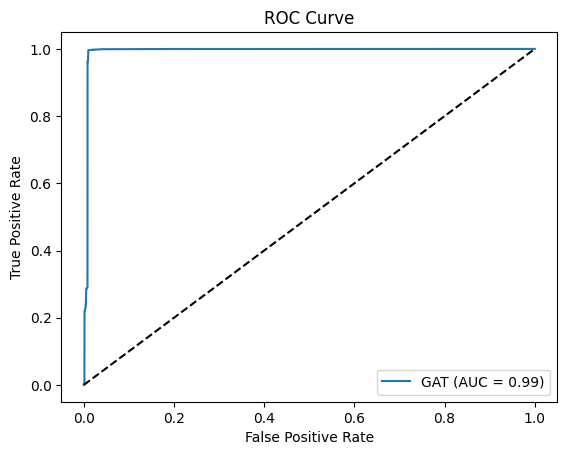


--- Début de la passe forward ---

[Forward] Entrée x shape : torch.Size([494021, 41])
[Forward] Après conv1 (SAGEConv) x shape : torch.Size([494021, 64])
[Forward] Après activation ReLU x shape : torch.Size([494021, 64])
[Forward] Après Dropout x shape : torch.Size([494021, 64])
[Forward] Après conv2 (SAGEConv) x shape : torch.Size([494021, 2])
Sortie du modèle (logits) shape : torch.Size([494021, 2])
Calcul de la loss sur les indices d'entraînement (345814 exemples) : 0.7479
Rétropropagation effectuée.
Optimiseur mis à jour.

--- Début de la passe forward ---

[Forward] Entrée x shape : torch.Size([494021, 41])
[Forward] Après conv1 (SAGEConv) x shape : torch.Size([494021, 64])
[Forward] Après activation ReLU x shape : torch.Size([494021, 64])
[Forward] Après Dropout x shape : torch.Size([494021, 64])
[Forward] Après conv2 (SAGEConv) x shape : torch.Size([494021, 2])
Sortie du modèle (logits) shape : torch.Size([494021, 2])
Calcul de la loss sur les indices d'entraînement (345814 ex

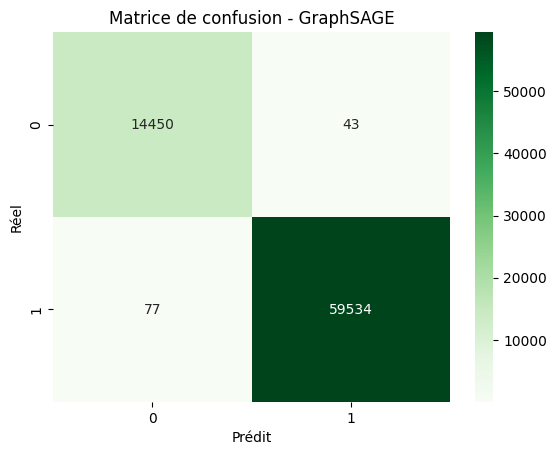

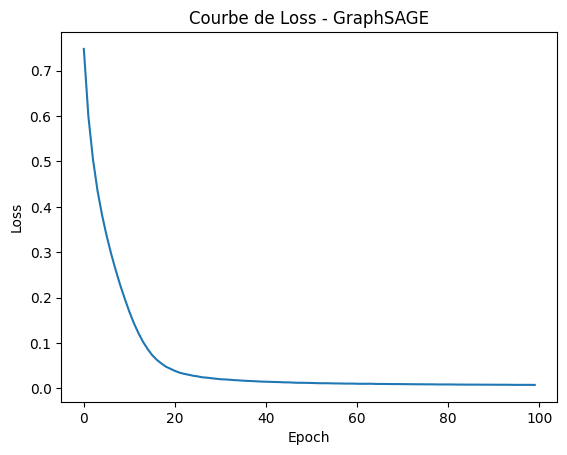

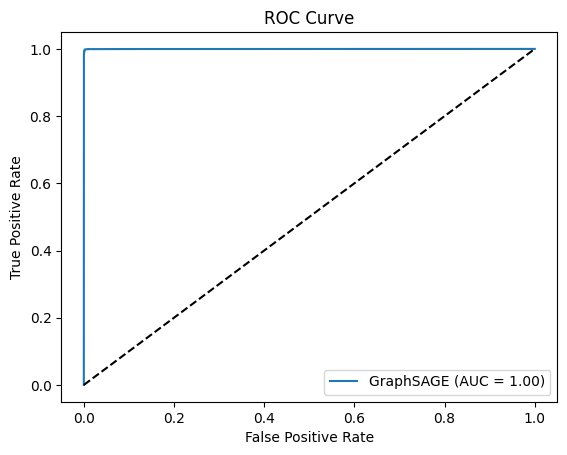

In [ ]:
run_model(GATNet, "GAT")
run_model(SAGENet, "GraphSAGE")
